# First Classification Model Pipeline

#### Proposed pipeline
`EMG + IMU → preprocessing → bilateral movement-state generation → state classification → bilateral transition validation → accepted motor state`

The data contains:
- 8 EMG channels
- 6 IMUs (left/right thigh, shank, foot)
- each IMU has Accel X/Y/Z and Gyro X/Y/Z
- standing baseline + five-step walking trial

### 1. Load the Libraries

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


### 2. Load the Data

In [8]:

from pathlib import Path

DATA_FILES = {
    "Walking": "Leen_walking_processed.csv",
    "Standing": "Leen_standing_processed.csv",
    "Elevate": "Leen_elevate_processed.csv",
    "Forward": "Leen_walking_forward_processed.csv",
}

# Locate the Leen folder
base = Path.cwd()

if (base / "Data" / "Leen").is_dir():
    data_folder = base / "Data" / "Leen"
elif (base / "Leen").is_dir():
    data_folder = base / "Leen"
else:
    raise FileNotFoundError(
        f"Cannot find the Leen data folder from {base}"
    )

recordings = {}

for name, filename in DATA_FILES.items():
    path = data_folder / filename

    if not path.is_file():
        print(f"Missing file: {path}")
        continue

    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.str.strip()
    recordings[name] = df

    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")


Missing file: c:\Users\leena\FES-Exoskeleton-Project\Data Analysis 2 - Leen\Data\Leen\Leen_walking_processed.csv
Standing: 14999 rows, 80 columns
Elevate: 75319 rows, 80 columns
Forward: 13519 rows, 80 columns


### 3. Identify EMG and IMU columns

In [9]:

# Time column
time_col = "Time_s"

# EMG muscles
muscles = [
    "Multifidus_R", "Multifidus_L",
    "ExternalOblique_R", "ExternalOblique_L",
    "RectusAbdominis_R", "RectusAbdominis_L",
    "ErectorSpinae_R", "ErectorSpinae_L"
]

# Use filtered EMG signals
emg_cols = [f"{muscle}_emg_filtered" for muscle in muscles]

# All 36 IMU measurements
imu_cols = [
    f"{location}_{side}_{signal}_{axis}"
    for side in ["L", "R"]
    for location in ["Thigh", "Shank", "Foot"]
    for signal in ["Accel", "Gyro"]
    for axis in ["X", "Y", "Z"]
]

required_cols = [time_col] + emg_cols + imu_cols

# Verify columns
for name, df in recordings.items():
    missing = set(required_cols) - set(df.columns)

    if missing:
        raise ValueError(f"{name} missing columns: {missing}")

print("EMG channels:", len(emg_cols))
print("IMU channels:", len(imu_cols))
print("Total required columns:", len(required_cols))


EMG channels: 8
IMU channels: 36
Total required columns: 45


### 4. Clean and validate the data

In [10]:

clean_recordings = {}

for name, df in recordings.items():
    df = df[required_cols].copy()

    # Convert columns to numeric
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan)

    # Remove rows with missing measurements
    df = df.dropna().reset_index(drop=True)

    # Require increasing timestamps
    df = df.loc[df[time_col].diff().fillna(1) > 0]
    df = df.reset_index(drop=True)

    if len(df) < 3:
        raise ValueError(f"{name}: insufficient valid samples")

    # Estimate sampling frequency
    dt = df[time_col].diff().dropna()
    fs = 1 / dt.median()

    clean_recordings[name] = (df, fs)

    print(f"{name}: {len(df)} valid samples")
    print(f"Estimated sampling rate: {fs:.2f} Hz")


Standing: 14990 valid samples
Estimated sampling rate: 2000.36 Hz
Elevate: 75311 valid samples
Estimated sampling rate: 2000.36 Hz
Forward: 13511 valid samples
Estimated sampling rate: 2000.36 Hz


### SECTION 5–6: Windowing, features, and data splitting

In [11]:

# SECTION 5–6: Windowing, features, and data splitting

WINDOW_MS = 20
STEP_MS = 20

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

feature_names = ["MAV", "RMS", "STD", "WL"]
feature_cols = [
    f"{col}_{feature}"
    for col in emg_cols
    for feature in feature_names
]

def extract_emg_features(x):
    mav = np.mean(np.abs(x), axis=0)
    rms = np.sqrt(np.mean(x ** 2, axis=0))
    std = np.std(x, axis=0)
    wl = np.mean(np.abs(np.diff(x, axis=0)), axis=0)

    return np.column_stack([mav, rms, std, wl]).ravel()


def make_windows(df, fs):
    size = max(2, round(fs * WINDOW_MS / 1000))
    step = max(1, round(fs * STEP_MS / 1000))

    emg = df[emg_cols].to_numpy(dtype=np.float32)
    imu = df[imu_cols].to_numpy(dtype=np.float32)
    times = df[time_col].to_numpy(dtype=float)

    features, targets, sequences, timestamps = [], [], [], []

    for start in range(0, len(df) - size + 1, step):
        end = start + size

        # Reject windows with discontinuous timestamps
        dt = np.diff(times[start:end])
        if np.any(dt <= 0) or np.any(dt > 2.5 / fs):
            continue

        x = emg[start:end]
        y = imu[end - 1]

        features.append(extract_emg_features(x))
        targets.append(y)
        sequences.append(x)
        timestamps.append(times[end - 1])

    return (
        np.asarray(features, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(sequences, dtype=np.float32),
        np.asarray(timestamps)
    )


parts = {
    "train": {"X": [], "y": [], "seq": [], "time": []},
    "val": {"X": [], "y": [], "seq": [], "time": []},
    "test": {"X": [], "y": [], "seq": [], "time": []}
}

for name, (df, fs) in clean_recordings.items():
    n = len(df)
    train_end = int(n * TRAIN_RATIO)
    val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

    segments = {
        "train": df.iloc[:train_end],
        "val": df.iloc[train_end:val_end],
        "test": df.iloc[val_end:]
    }

    print(f"\n{name}:")

    for split_name, segment in segments.items():
        X, y, seq, times = make_windows(segment, fs)

        if len(X) == 0:
            raise ValueError(f"{name}: no {split_name} windows")

        parts[split_name]["X"].append(X)
        parts[split_name]["y"].append(y)
        parts[split_name]["seq"].append(seq)
        parts[split_name]["time"].append(times)

        print(f"  {split_name}: {len(X)} windows")


def combine(split_name):
    p = parts[split_name]

    return (
        pd.DataFrame(np.vstack(p["X"]), columns=feature_cols),
        pd.DataFrame(np.vstack(p["y"]), columns=imu_cols),
        np.concatenate(p["seq"]),
        np.concatenate(p["time"])
    )


X_train, y_train, X_train_seq, time_train = combine("train")
X_val, y_val, X_val_seq, time_val = combine("val")
X_test, y_test, X_test_seq, time_test = combine("test")

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("CNN/LSTM shape:", X_train_seq.shape)



Standing:
  train: 262 windows
  val: 56 windows
  test: 56 windows

Elevate:
  train: 1317 windows
  val: 282 windows
  test: 282 windows

Forward:
  train: 236 windows
  val: 50 windows
  test: 50 windows

Training: (1815, 32)
Validation: (388, 32)
Testing: (388, 32)
CNN/LSTM shape: (1815, 40, 8)


### 7. Train the three regression models

In [12]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=3,
        n_jobs=-1,
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        MultiOutputRegressor(
            SVR(kernel="rbf", C=10, epsilon=0.1),
            n_jobs=-1
        )
    ),

    "Gradient Boosting": MultiOutputRegressor(
        HistGradientBoostingRegressor(
            max_iter=100,
            learning_rate=0.05,
            max_leaf_nodes=15,
            random_state=42
        ),
        n_jobs=-1
    ),

    "Baseline": DummyRegressor(strategy="mean"),

    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )
}

predictions = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

print("Traditional models completed.")



Training Random Forest...
Training SVM...
Training Gradient Boosting...
Training Baseline...
Training Ridge...
Traditional models completed.


In [13]:

# Scale EMG sequences
n_channels = len(emg_cols)

emg_scaler = StandardScaler()

emg_scaler.fit(
    X_train_seq.reshape(-1, n_channels)
)

def scale_sequences(data):
    shape = data.shape

    return emg_scaler.transform(
        data.reshape(-1, n_channels)
    ).reshape(shape).astype(np.float32)


X_train_nn = scale_sequences(X_train_seq)
X_val_nn = scale_sequences(X_val_seq)
X_test_nn = scale_sequences(X_test_seq)

# Scale IMU targets
imu_scaler = StandardScaler()

y_train_nn = imu_scaler.fit_transform(y_train).astype(np.float32)
y_val_nn = imu_scaler.transform(y_val).astype(np.float32)

print("Training:", X_train_nn.shape)
print("Validation:", X_val_nn.shape)
print("Testing:", X_test_nn.shape)


Training: (1815, 40, 8)
Validation: (388, 40, 8)
Testing: (388, 40, 8)


In [14]:

def build_cnn(input_shape, output_size):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv1D(32, 7, padding="same", activation="relu"),
        layers.MaxPooling1D(2),

        layers.Conv1D(64, 5, padding="same", activation="relu"),
        layers.MaxPooling1D(2),

        layers.Conv1D(64, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),

        layers.Dense(64, activation="relu"),
        layers.Dense(output_size)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="mse"
    )

    return model


cnn = build_cnn(
    X_train_nn.shape[1:],
    len(imu_cols)
)


In [15]:

def build_lstm(input_shape, output_size):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        layers.LSTM(64),
        layers.Dense(64, activation="relu"),
        layers.Dense(output_size)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="mse"
    )

    return model


lstm = build_lstm(
    X_train_nn.shape[1:],
    len(imu_cols)
)


In [16]:

neural_models = {
    "CNN": cnn,
    "LSTM": lstm
}

histories = {}

for name, model in neural_models.items():
    print(f"\nTraining {name}...")

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_nn,
        y_train_nn,
        validation_data=(X_val_nn, y_val_nn),
        epochs=50,
        batch_size=64,
        callbacks=[early_stop],
        shuffle=False,
        verbose=1
    )

    histories[name] = history

    pred_scaled = model.predict(
        X_test_nn,
        verbose=0
    )

    predictions[name] = imu_scaler.inverse_transform(
        pred_scaled
    )

print("\nAll seven models completed.")



Training CNN...
Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 1.0226 - val_loss: 1.2663
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.0006 - val_loss: 1.2650
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9990 - val_loss: 1.2639
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9966 - val_loss: 1.2613
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9903 - val_loss: 1.2516
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.9747 - val_loss: 1.2304
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.9484 - val_loss: 1.2097
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9199 - val_loss: 1.1961
Epoch 9/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8920 - val_loss: 1.1790
Epoch 10/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8724 - val_loss: 1.1685
Epoch 11/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8607 - val_loss: 1.1597
Epoch 12/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - l

### 8. Evaluate and compare the models

In [17]:

results = []

actual = y_test.to_numpy()

target_scale = y_train.std(axis=0).to_numpy()
target_scale = np.where(target_scale > 1e-12, target_scale, 1.0)

for name, pred in predictions.items():
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))

    r2 = r2_score(
        actual,
        pred,
        multioutput="raw_values"
    )

    per_channel_rmse = np.sqrt(
        np.mean((actual - pred) ** 2, axis=0)
    )

    nrmse = np.mean(per_channel_rmse / target_scale)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "NRMSE": nrmse,
        "Mean R2": np.mean(r2)
    })

comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    "NRMSE"
).reset_index(drop=True)

display(comparison.round(4))


,Model,MAE,RMSE,NRMSE,Mean R2
0,Random Forest,47.1600,99.6777,0.9039,0.1323
1,CNN,53.3786,103.2229,0.9228,0.0959
2,Gradient Boosting,49.8096,102.0276,0.9270,0.0761
3,LSTM,53.7058,109.1671,0.9412,0.0691
4,SVM,52.9764,116.0984,0.9457,0.0784
5,Ridge,58.5673,113.6491,0.9540,0.0428
6,Baseline,73.4247,138.8147,1.0132,-0.0514


### 9. Evaluate each IMU location separately

In [18]:

location_results = []

for name, pred in predictions.items():
    pred_df = pd.DataFrame(pred, columns=imu_cols)

    for location in ["Thigh", "Shank", "Foot"]:
        for side in ["L", "R"]:
            cols = [
                c for c in imu_cols
                if c.startswith(f"{location}_{side}_")
            ]

            actual = y_test[cols].to_numpy()
            estimated = pred_df[cols].to_numpy()

            location_results.append({
                "Model": name,
                "Location": location,
                "Side": side,
                "R2": r2_score(actual, estimated)
            })

location_comparison = pd.DataFrame(location_results)
display(location_comparison)


,Model,Location,Side,R2
0,Random Forest,Thigh,L,0.341386
1,Random Forest,Thigh,R,0.161805
2,Random Forest,Shank,L,0.086324
3,Random Forest,Shank,R,0.008067
4,Random Forest,Foot,L,0.141713
5,Random Forest,Foot,R,0.054214
6,SVM,Thigh,L,0.188390
7,SVM,Thigh,R,0.197512
8,SVM,Shank,L,0.015756
9,SVM,Shank,R,0.005727


### 10. Visualize actual vs. predicted IMU signals

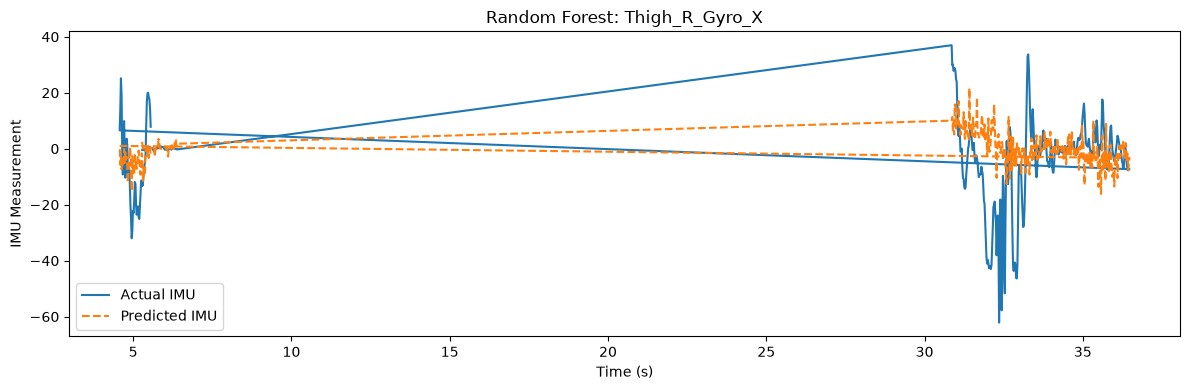

In [19]:

BEST_MODEL = comparison.sort_values("NRMSE").iloc[0]["Model"]

CHANNEL = "Thigh_R_Gyro_X"

actual = y_test[CHANNEL].to_numpy()
pred = pd.DataFrame(
    predictions[BEST_MODEL],
    columns=imu_cols
)[CHANNEL].to_numpy()

plt.figure(figsize=(12, 4))

plt.plot(time_test, actual, label="Actual IMU")
plt.plot(time_test, pred, label="Predicted IMU", linestyle="--")

plt.title(f"{BEST_MODEL}: {CHANNEL}")
plt.xlabel("Time (s)")
plt.ylabel("IMU Measurement")
plt.legend()
plt.tight_layout()
plt.show()


### 11. Predict IMU measurements from new EMG data

In [20]:

BEST_MODEL = comparison.iloc[0]["Model"]

# Display the first prediction from the best model
predicted_imu = pd.DataFrame(
    predictions[BEST_MODEL][:1],
    columns=imu_cols
)

print("Best model:", BEST_MODEL)
display(predicted_imu.T)


Best model: Random Forest


,0
Thigh_L_Accel_X,975.322380
Thigh_L_Accel_Y,79.283179
Thigh_L_Accel_Z,-60.531341
Thigh_L_Gyro_X,1.895617
Thigh_L_Gyro_Y,-2.578286
Thigh_L_Gyro_Z,5.493768
Shank_L_Accel_X,990.881901
Shank_L_Accel_Y,-73.466222
Shank_L_Accel_Z,37.401039
Shank_L_Gyro_X,-2.671678


### Section 12 — Generate provisional gait-phase labels

In [21]:

# SECTION 12: Estimate gait phases from actual IMU data

from scipy.signal import find_peaks, savgol_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

PHASES = [
    "Heel Strike",
    "Loading Response",
    "Mid Stance",
    "Terminal Stance",
    "Pre-Swing"
]

# Approximate fractions of a complete gait cycle
# Remaining 38% is swing and is excluded.
PHASE_BOUNDARIES = [0.02, 0.12, 0.31, 0.50, 0.62]

def estimate_phases(imu_data, times):
    labels = np.full(len(imu_data), -1, dtype=int)

    foot_cols = [
        "Foot_L_Accel_X",
        "Foot_L_Accel_Y",
        "Foot_L_Accel_Z"
    ]

    accel = imu_data[foot_cols].to_numpy()
    magnitude = np.linalg.norm(accel, axis=1)

    if len(times) < 10:
        return labels

    dt = np.median(np.diff(times))
    if dt <= 0:
        return labels

    fs = 1 / dt

    # Smooth the acceleration magnitude
    smooth_size = max(5, int(fs * 0.08) | 1)
    if smooth_size >= len(magnitude):
        return labels

    signal = savgol_filter(magnitude, smooth_size, 2)

    # Candidate foot-contact peaks
    peaks, _ = find_peaks(
        signal,
        distance=max(1, int(fs * 0.4)),
        prominence=max(0.01, np.std(signal) * 0.4)
    )

    # Label cycles between consecutive candidate contacts
    for i in range(len(peaks) - 1):
        start = peaks[i]
        end = peaks[i + 1]

        duration = times[end] - times[start]

        # Reject implausibly short or long gait cycles
        if not 0.4 <= duration <= 2.0:
            continue

        cycle_time = (times[start:end] - times[start]) / duration

        for phase_id, boundary in enumerate(PHASE_BOUNDARIES):
            lower = 0 if phase_id == 0 else PHASE_BOUNDARIES[phase_id - 1]

            selected = (
                (cycle_time >= lower) &
                (cycle_time < boundary)
            )

            labels[np.arange(start, end)[selected]] = phase_id

    return labels


### Section 13 — Prepare classification labels

In [22]:

# SECTION 13: Create labels for training and testing

def create_split_labels(split_name):
    labels_all = []

    for i, name in enumerate(clean_recordings.keys()):
        y_part = pd.DataFrame(
            parts[split_name]["y"][i],
            columns=imu_cols
        )
        times = parts[split_name]["time"][i]

        if name.lower() in ["walking", "forward"]:
            labels = estimate_phases(y_part, times)
        else:
            labels = np.full(len(y_part), -1, dtype=int)

        print(
            split_name, name,
            "labeled:", np.sum(labels >= 0),
            "/", len(labels)
        )

        labels_all.append(labels)

    return np.concatenate(labels_all)


phase_train = create_split_labels("train")
phase_test = create_split_labels("test")

train_mask = phase_train >= 0
test_mask = phase_test >= 0

if not train_mask.any() or not test_mask.any():
    raise ValueError(
        "No valid gait phases detected. "
        "Inspect the IMU signals and peak detection."
    )

print("\nTraining phase distribution:")
print(pd.Series(phase_train[train_mask]).map(
    dict(enumerate(PHASES))
).value_counts())


train Standing labeled: 0 / 262
train Elevate labeled: 0 / 1317
train Forward labeled: 58 / 236
test Standing labeled: 0 / 56
test Elevate labeled: 0 / 282
test Forward labeled: 16 / 50

Training phase distribution:
Terminal Stance     18
Mid Stance          17
Pre-Swing           11
Loading Response     9
Heel Strike          3
Name: count, dtype: int64


### Section 14 — Train and evaluate the classifier

In [23]:

# SECTION 14: Gait phase classification

classifier = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

classifier.fit(
    y_train.to_numpy()[train_mask],
    phase_train[train_mask]
)

results_stage2 = []

# First: classification using actual IMU
inputs = {
    "Actual IMU": y_test.to_numpy(),
    **predictions
}

phase_predictions = {}

for name, imu_values in inputs.items():
    predicted_phases = classifier.predict(
        np.asarray(imu_values)[test_mask]
    )

    phase_predictions[name] = predicted_phases

    results_stage2.append({
        "Model": name,
        "Accuracy": accuracy_score(
            phase_test[test_mask],
            predicted_phases
        ),
        "Macro F1": f1_score(
            phase_test[test_mask],
            predicted_phases,
            average="macro",
            zero_division=0
        )
    })

stage2_comparison = pd.DataFrame(results_stage2)

display(
    stage2_comparison.sort_values(
        "Accuracy", ascending=False
    ).round(4)
)


,Model,Accuracy,Macro F1
0,Actual IMU,0.6250,0.4333
1,Random Forest,0.3125,0.1000
2,SVM,0.3125,0.0952
3,Gradient Boosting,0.3125,0.0952
4,Baseline,0.3125,0.0952
5,Ridge,0.3125,0.0952
6,CNN,0.3125,0.0952
7,LSTM,0.3125,0.0952


### Section 15 — Confusion matrix

Regression model: Random Forest
                  precision    recall  f1-score   support

     Heel Strike       0.00      0.00      0.00         1
Loading Response       0.00      0.00      0.00         3
      Mid Stance       0.00      0.00      0.00         4
 Terminal Stance       0.33      1.00      0.50         5
       Pre-Swing       0.00      0.00      0.00         3

        accuracy                           0.31        16
       macro avg       0.07      0.20      0.10        16
    weighted avg       0.10      0.31      0.16        16



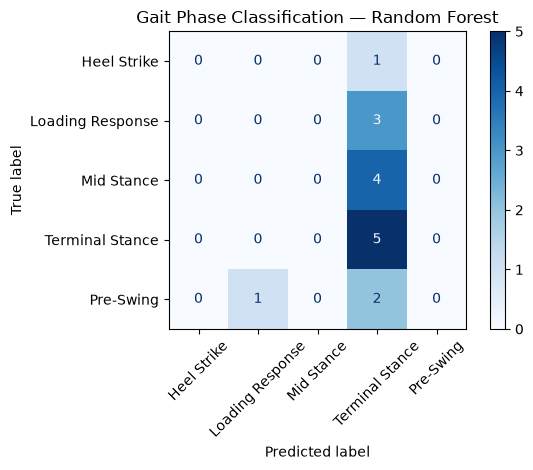

In [24]:

# SECTION 15: Confusion matrix for best regression model

best_regression = comparison.iloc[0]["Model"]

print("Regression model:", best_regression)

print(classification_report(
    phase_test[test_mask],
    phase_predictions[best_regression],
    labels=range(5),
    target_names=PHASES,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    phase_test[test_mask],
    phase_predictions[best_regression],
    labels=range(5),
    display_labels=PHASES,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title(f"Gait Phase Classification — {best_regression}")
plt.tight_layout()
plt.show()
